# 04 · Optimización de hiperparámetros y análisis de sensibilidad

Workshop S5. Pregunta: **¿cuánto mejora el modelo base si se buscan sistemáticamente los hiperparámetros, y a cuáles es realmente sensible?** La respuesta condiciona la elección de `best_model`.

Método (`src/genial_clf/optimize.py`, ejecutado por `scripts/optimizar.py`):

1. **Búsqueda bayesiana** con Optuna (muestreador TPE, 15 ensayos iniciales aleatorios, 60 en total). Función objetivo: F1 macro en validación cruzada estratificada por grupo de URL (5 pliegues) sobre el conjunto de entrenamiento. El primer ensayo es la configuración base, para que la historia parta de ella.
2. **Ranking de importancia** de hiperparámetros (fANOVA sobre los ensayos).
3. **Dependencia parcial 1-D**: barrido de cada hiperparámetro con los demás fijos en el óptimo.
4. **Interacción** `C × max_features` (dependencia parcial 2-D).
5. **Tabla de sensibilidad**: rango explorado, valor óptimo y variación del F1 (máx − mín) en el barrido.
6. **Antes / después** con la configuración base, el óptimo de Optuna y la **regla de una desviación estándar** (entre los ensayos a ≤ 1 DE del máximo, el de menor *gap* entrenamiento − validación), que es la que se adopta.

Espacio de búsqueda:

| Hiperparámetro | Rango | Tipo |
|---|---|---|
| `C` (inverso de la regularización L2) | 0.01 – 30 | continuo, escala log |
| `max_features` | {1 000, 2 000, 3 000, 5 000, 8 000, 12 000, 20 000} | categórico |
| `ngram_max` | {1, 2} | categórico |
| `min_df` | {1, 2, 3} | categórico |
| `class_weight` | {balanced, None} | categórico |
| `sublinear_tf` | {True, False} | categórico |

El conjunto ciego **no interviene** en ningún paso.

In [1]:
import json, os, subprocess, sys, time, warnings
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, display, Markdown
warnings.filterwarnings("ignore")
pd.set_option("display.width", 160); pd.set_option("display.max_columns", 30)
ROOT = Path.cwd() if (Path.cwd() / "config.yaml").exists() else Path.cwd().parent
os.chdir(ROOT); sys.path.insert(0, str(ROOT / "src"))
from utils import load_config, setup_logging, set_seed, CLASSES
cfg = load_config(); set_seed(cfg["seed"]); setup_logging()
RES = ROOT / "results/metrics"; FIG = ROOT / "results/figures"; RES.mkdir(parents=True, exist_ok=True); FIG.mkdir(parents=True, exist_ok=True)
print("raíz del repositorio:", ROOT)

raíz del repositorio: /home/claude/repo_genial


## 1. Ejecutar o reutilizar la búsqueda

La búsqueda completa (60 ensayos + barridos ≈ 200 ajustes de modelo) tarda unos seis minutos. Si `results/metrics/optimizacion/resumen.json` existe se reutiliza; cambie `EJECUTAR = True` para repetirla.

In [2]:
EJECUTAR = False; N_TRIALS = 60
OPT = RES / "optimizacion"
if EJECUTAR or not (OPT / "resumen.json").exists():
    sys.argv = ["optimizar"]; import importlib.util
    spec = importlib.util.spec_from_file_location("optimizar", ROOT / "scripts/optimizar.py"); m = importlib.util.module_from_spec(spec); spec.loader.exec_module(m)
    resumen = m.main(N_TRIALS, cfg["seed"])
else:
    resumen = json.loads((OPT / "resumen.json").read_text(encoding="utf-8")); print("resultados reutilizados de", OPT)
trials = pd.read_csv(OPT / "trials.csv"); print(resumen["n_trials"], "ensayos ·", resumen["segundos"], "s")

resultados reutilizados de /home/claude/repo_genial/results/metrics/optimizacion
60 ensayos · 323.7 s


## 2. Historia de la búsqueda

Cada punto es un ensayo; la línea, el mejor F1 hasta ese momento; la discontinua, la configuración base. Lo primero que se observa es que **la nube es estrecha**: más de la mitad de los ensayos quedan en ±2 pp del valor base.

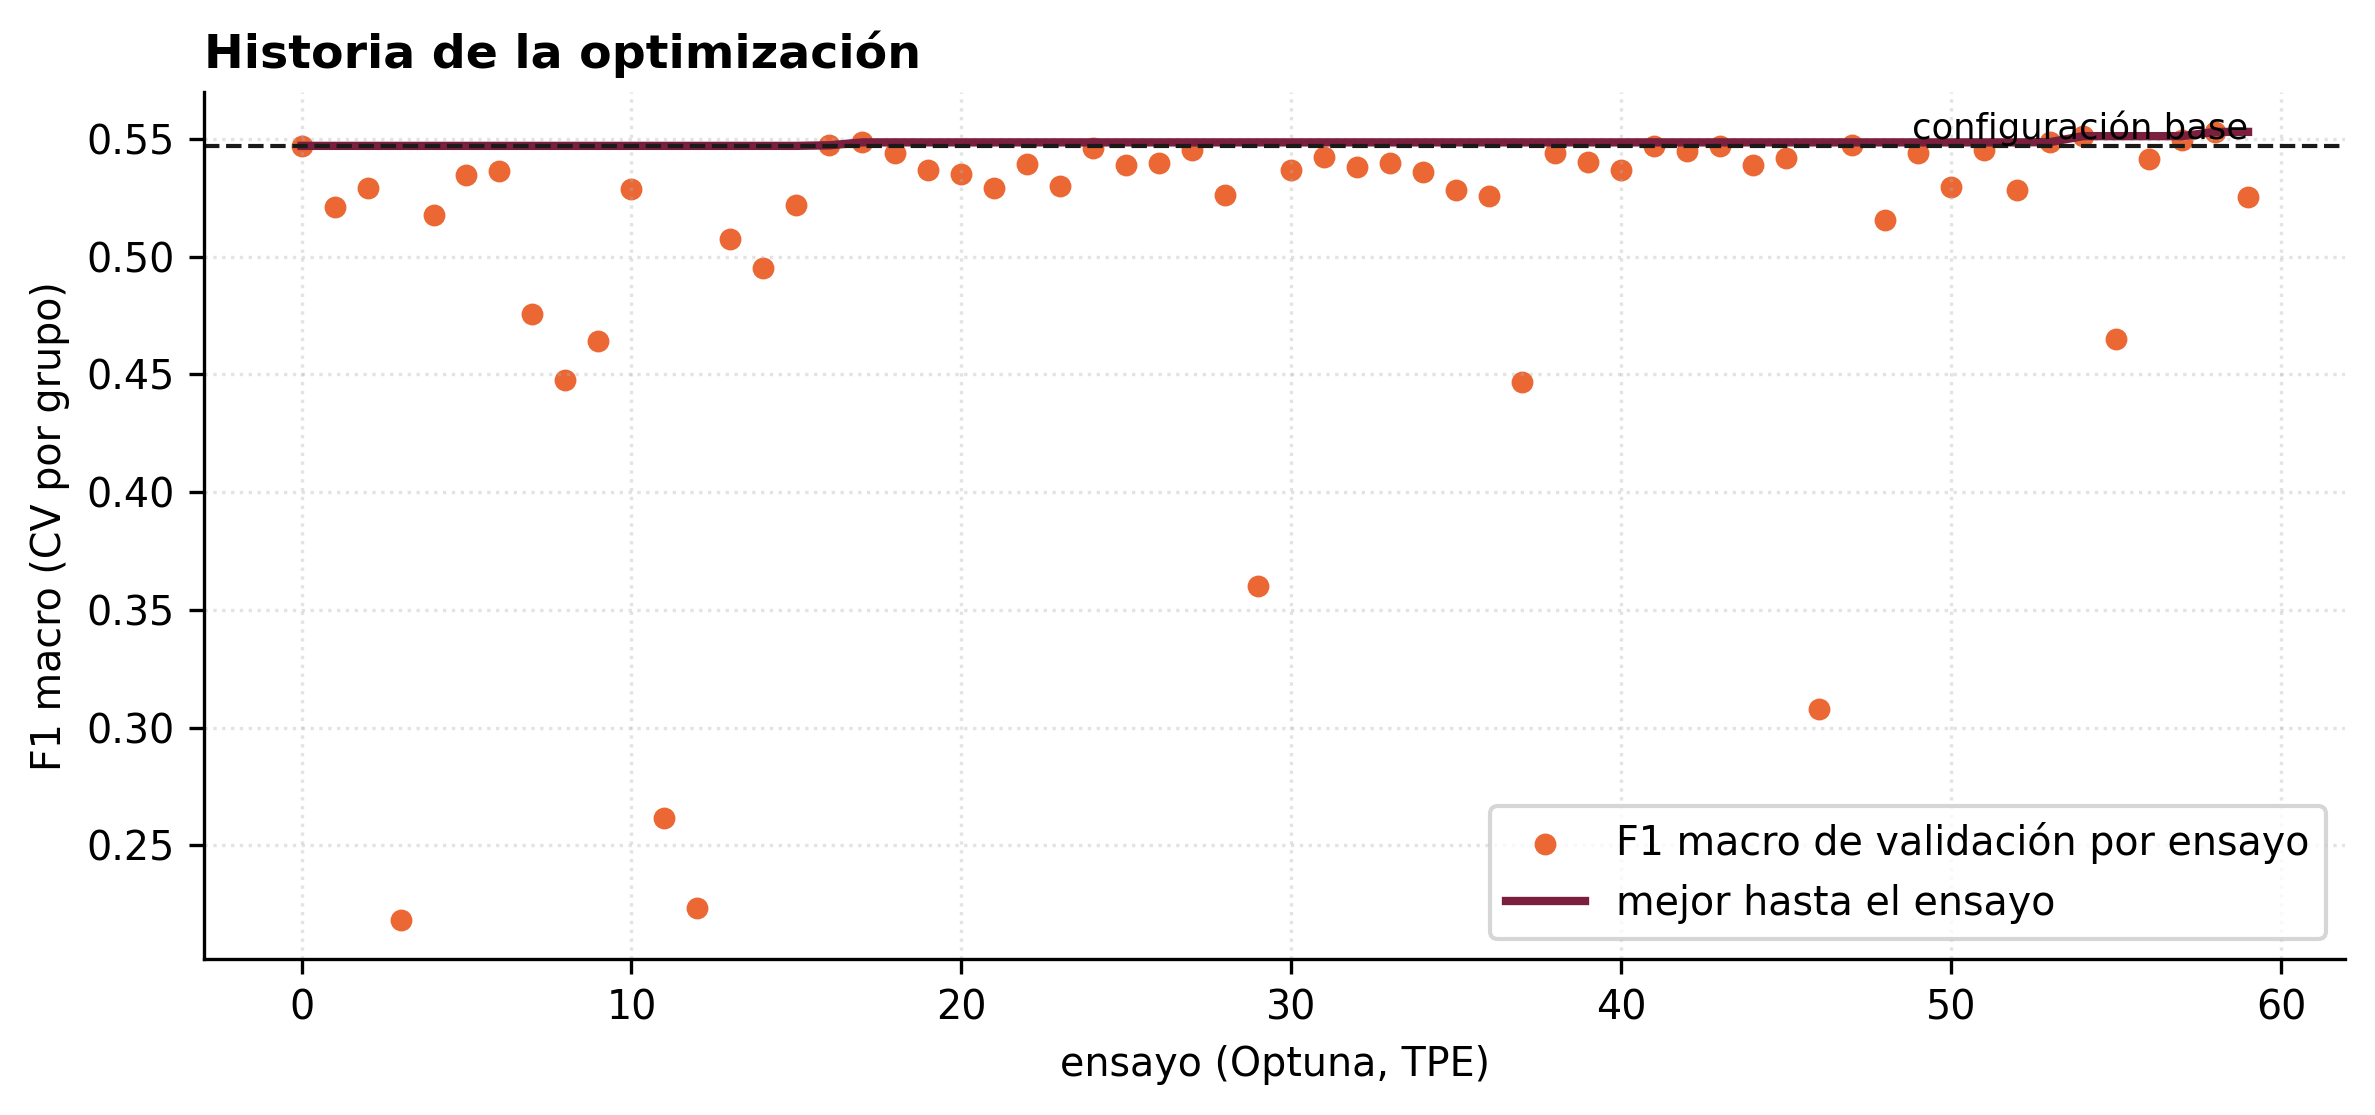

,trial,val_f1,train_f1,gap,C,max_features,ngram_max,min_df,class_weight,sublinear_tf
58,58,0.553,0.994,0.441,3.041,8000,2,1,balanced,True
54,54,0.551,0.995,0.444,3.579,8000,2,1,balanced,True
57,57,0.550,0.995,0.445,4.613,8000,2,1,balanced,True
53,53,0.549,0.943,0.394,0.724,8000,2,1,balanced,True
17,17,0.549,0.861,0.313,0.446,2000,2,1,balanced,True
47,47,0.547,0.854,0.307,0.384,2000,2,1,balanced,True
16,16,0.547,0.899,0.352,0.243,8000,2,1,balanced,True
43,43,0.547,0.944,0.397,1.036,5000,2,1,balanced,True


base (ensayo 0): val F1 0.547 · gap 0.40


In [3]:
display(Image(filename=str(FIG / "13_optuna_historia.png"), width=820))
mejor = trials.sort_values("val_f1", ascending=False).head(8)[["trial", "val_f1", "train_f1", "gap", "C", "max_features", "ngram_max", "min_df", "class_weight", "sublinear_tf"]]
display(mejor.round(3)); print("base (ensayo 0): val F1 %.3f · gap %.2f" % (trials.loc[0, "val_f1"], trials.loc[0, "gap"]))

## 3. Ranking de importancia (fANOVA)

Qué fracción de la varianza del F1 entre ensayos explica cada hiperparámetro. **`class_weight` domina** (≈ 0.77): es la decisión que separa los ensayos buenos de los malos. `C` queda segundo; el resto es casi irrelevante dentro del rango explorado.

,hiperparámetro,importancia
0,class_weight,0.769
1,C,0.181
2,max_features,0.029
3,min_df,0.013
4,sublinear_tf,0.007
5,ngram_max,0.002


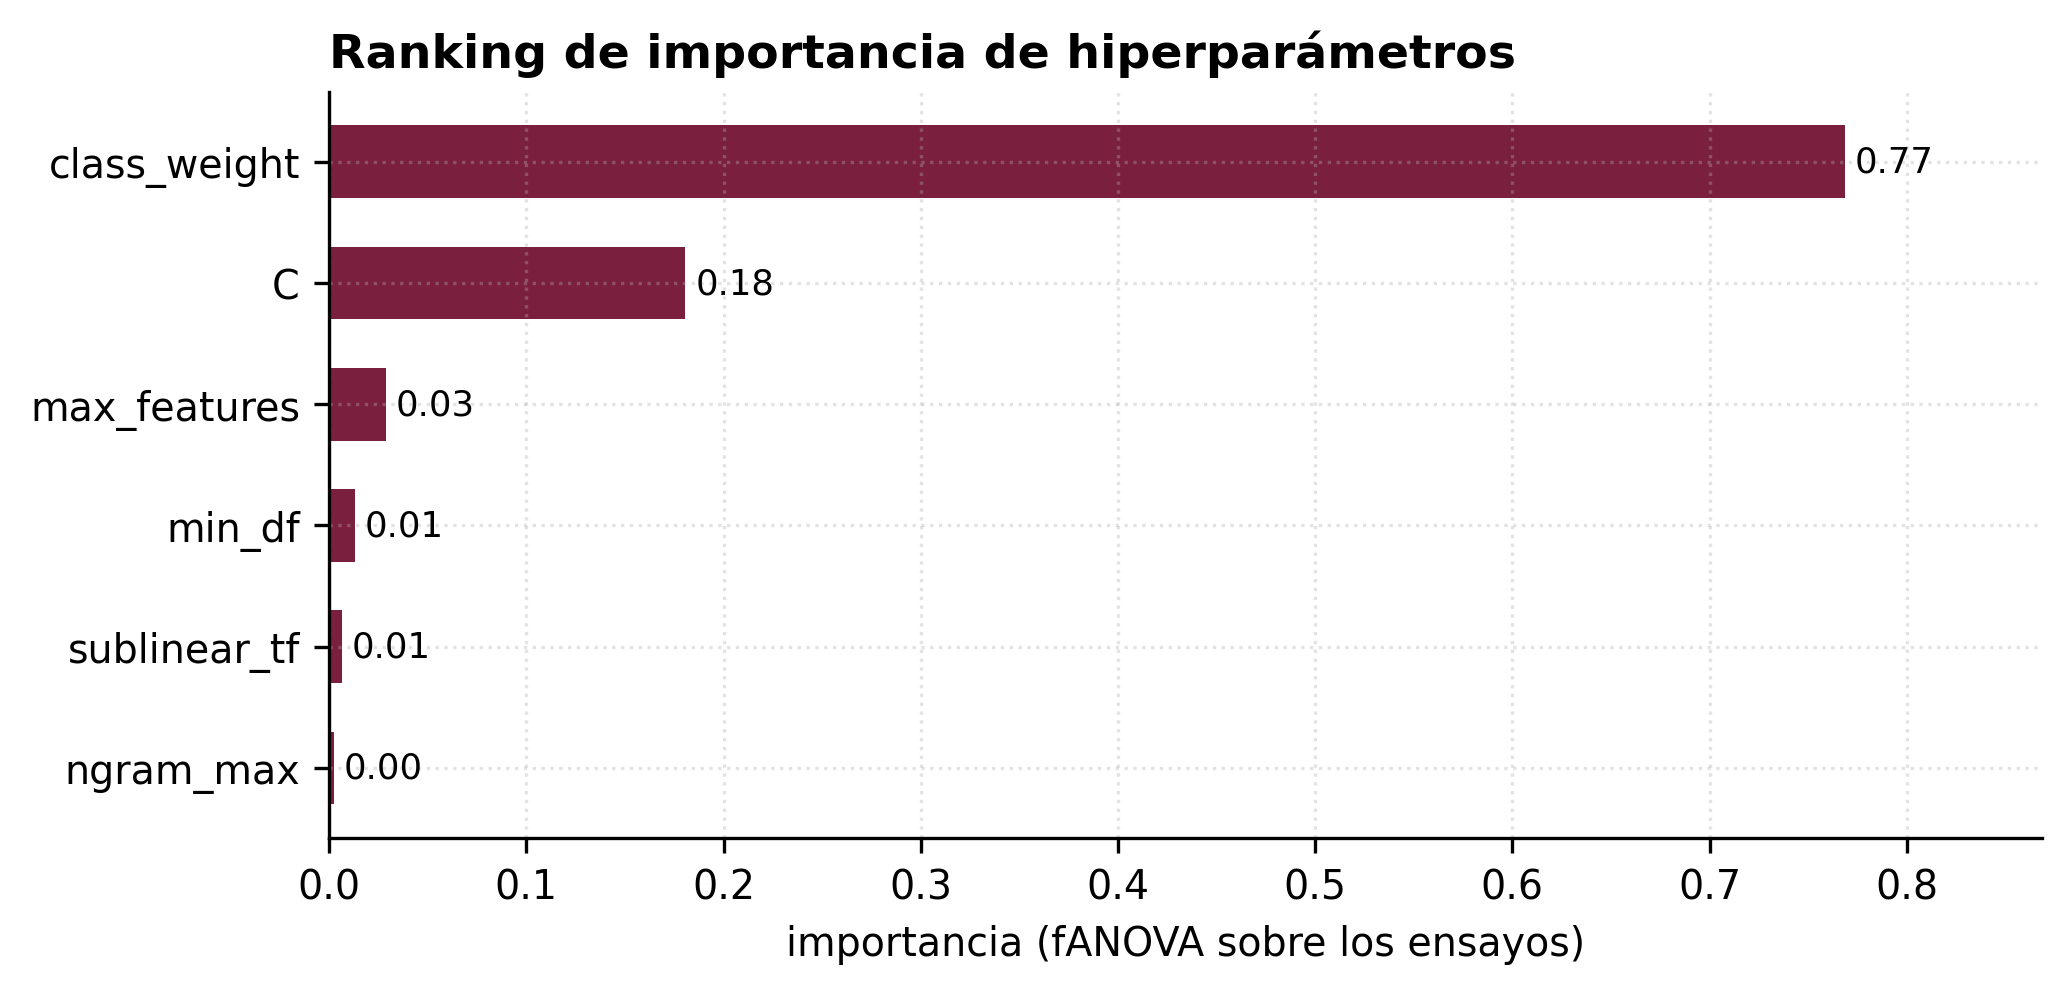

In [4]:
display(pd.read_csv(OPT / "importancia.csv").round(3)); display(Image(filename=str(FIG / "14_importancia_hiperparametros.png"), width=700))

## 4. Dependencia parcial y tabla de sensibilidad

Barrido de cada hiperparámetro con los demás en el óptimo. La banda es ± 1 DE entre pliegues. Lectura: la curva de validación es **plana** en casi todos los paneles (la variación máx − mín no supera 3 pp), mientras la de entrenamiento sube con `C` y con el vocabulario: el modelo puede memorizar más, pero no generaliza más.

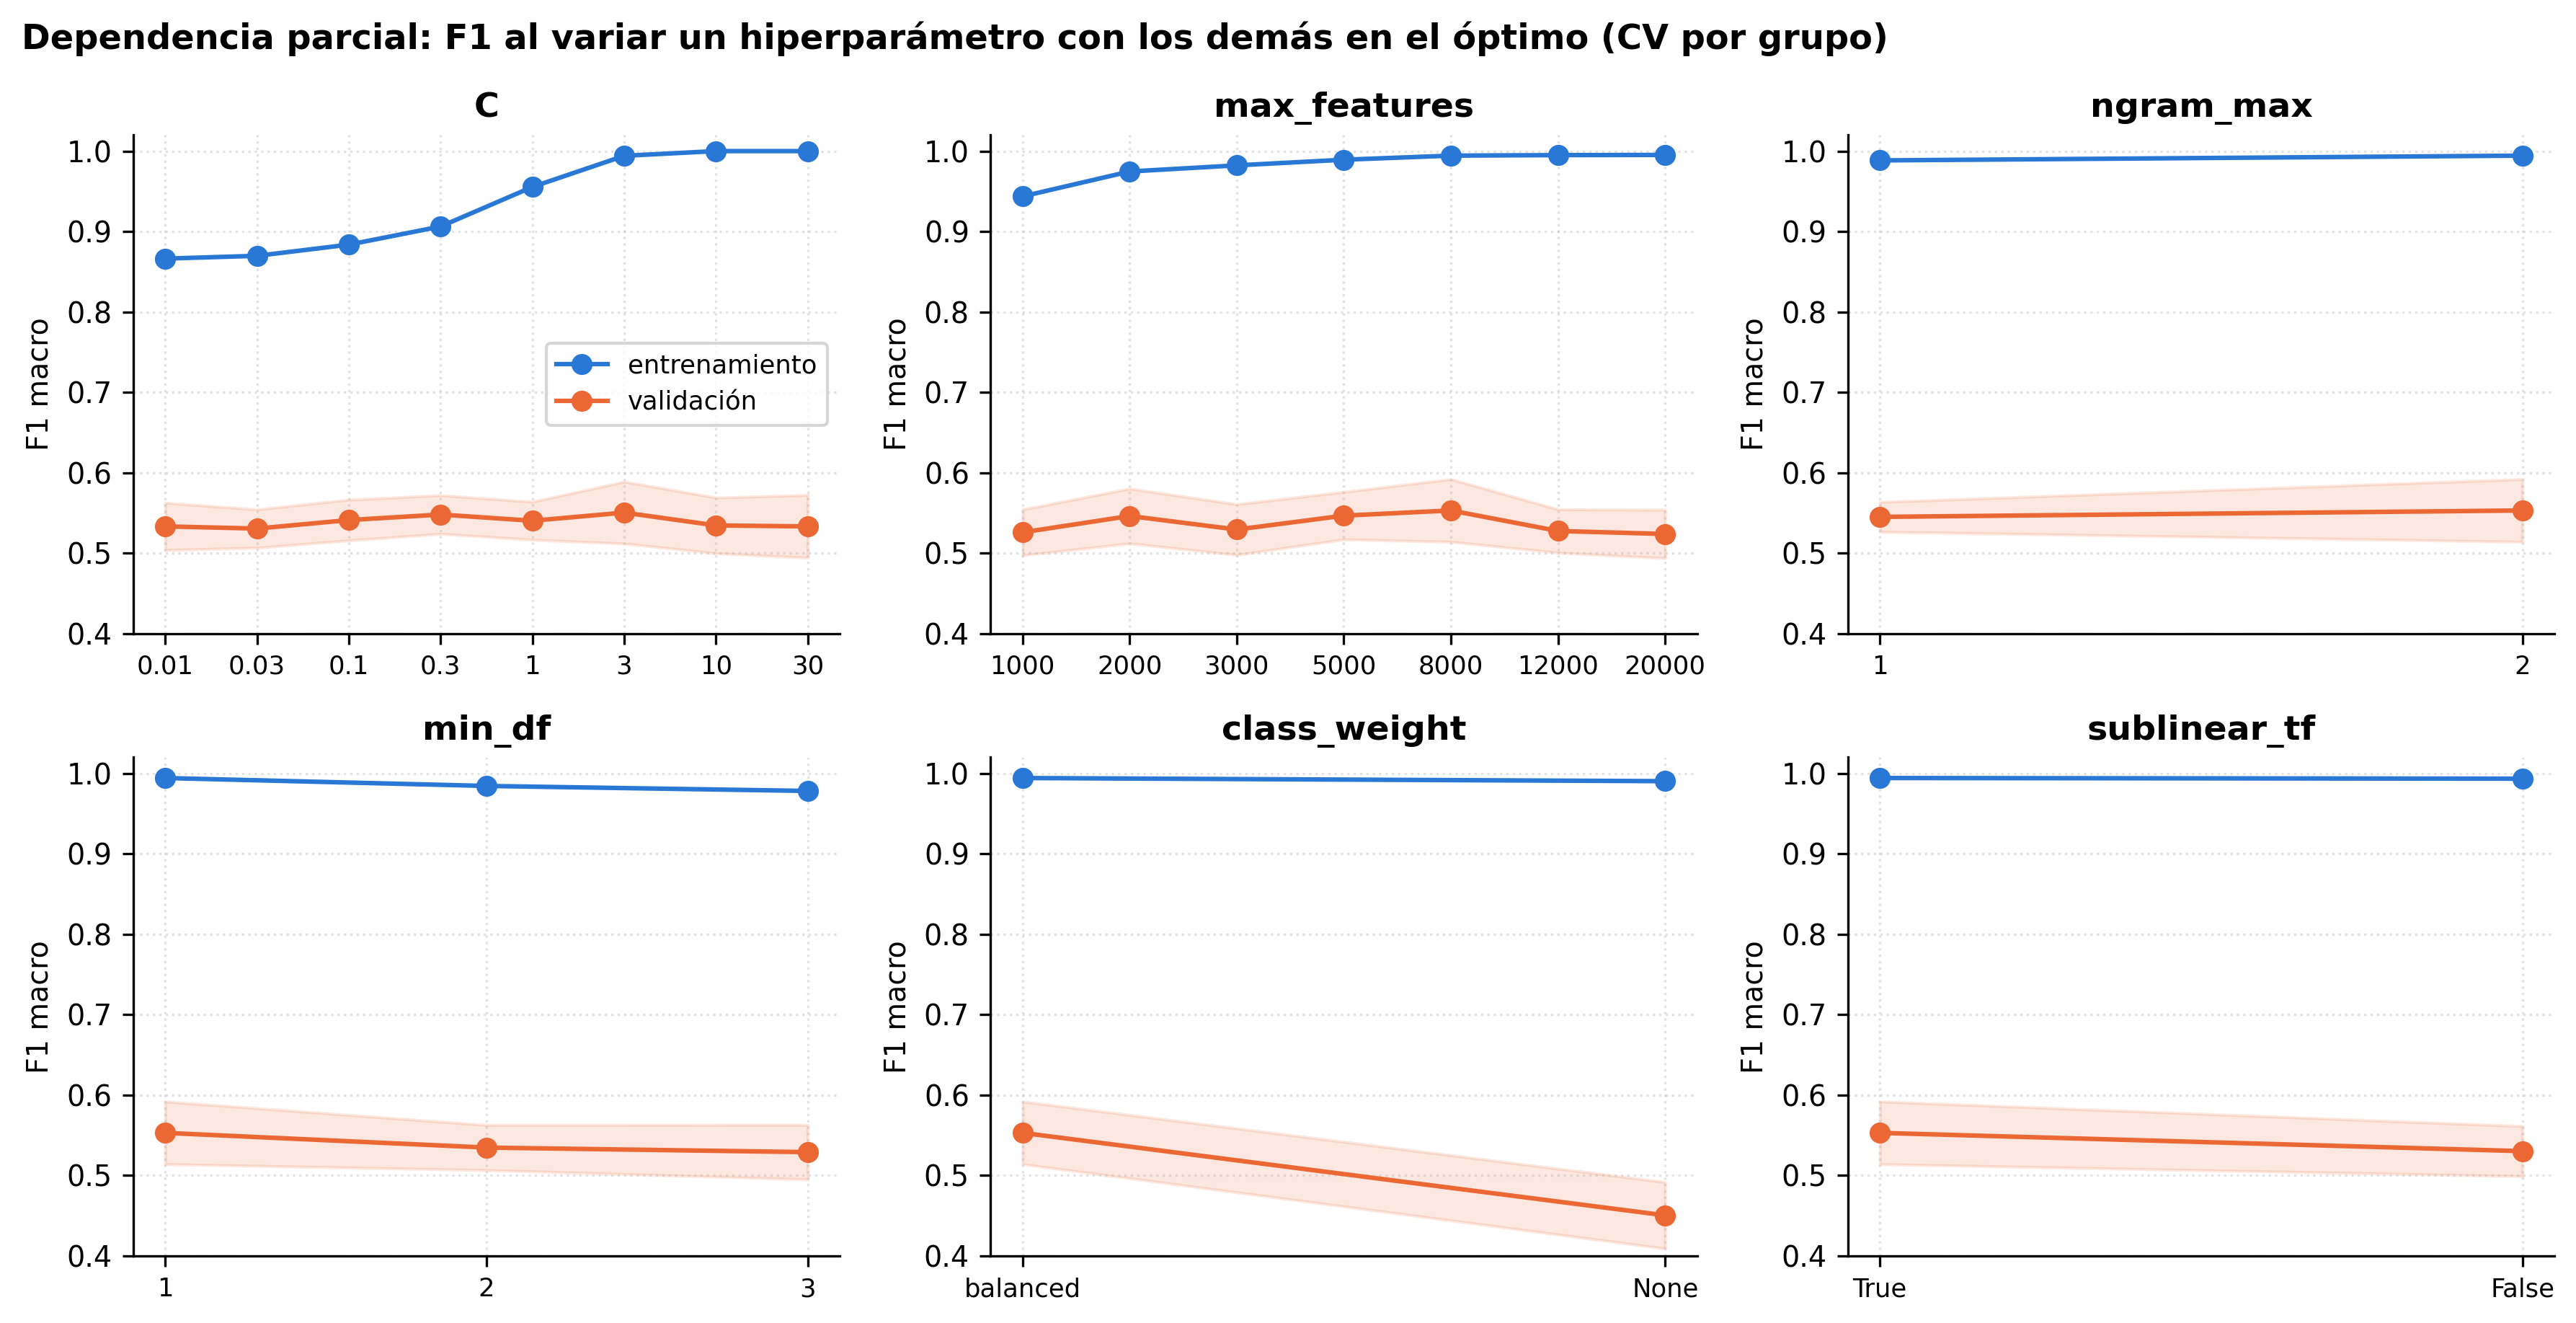

,hiperparámetro,valores explorados,valor óptimo,F1 val. mín,F1 val. máx,variación (pp),gap mín,gap máx
0,class_weight,"balanced, None",balanced,0.450,0.553,10.259,0.441,0.540
1,max_features,"1000, 2000, 3000, 5000, 8000, 12000, 20000",8000,0.524,0.553,2.923,0.418,0.471
2,min_df,"1, 2, 3",1,0.529,0.553,2.397,0.441,0.450
3,sublinear_tf,"True, False",True,0.530,0.553,2.274,0.441,0.463
4,C,"0.01, 0.03, 0.1, 0.3, 1, 3, 10, 30",3.041348095884574,0.530,0.550,1.985,0.333,0.467
5,ngram_max,"1, 2",2,0.545,0.553,0.799,0.441,0.443


In [5]:
display(Image(filename=str(FIG / "15_dependencia_parcial.png"), width=1000))
sens = pd.read_csv(OPT / "sensibilidad.csv"); display(sens.round(3))

## 5. Interacción `C × max_features`

Mapa de calor del F1 de validación (izquierda) y del *gap* (derecha). El F1 es casi constante sobre toda la rejilla; el *gap*, en cambio, crece con ambos ejes. De ahí la regla de decisión: **a igual F1, la esquina de menor `C` y menor vocabulario**.

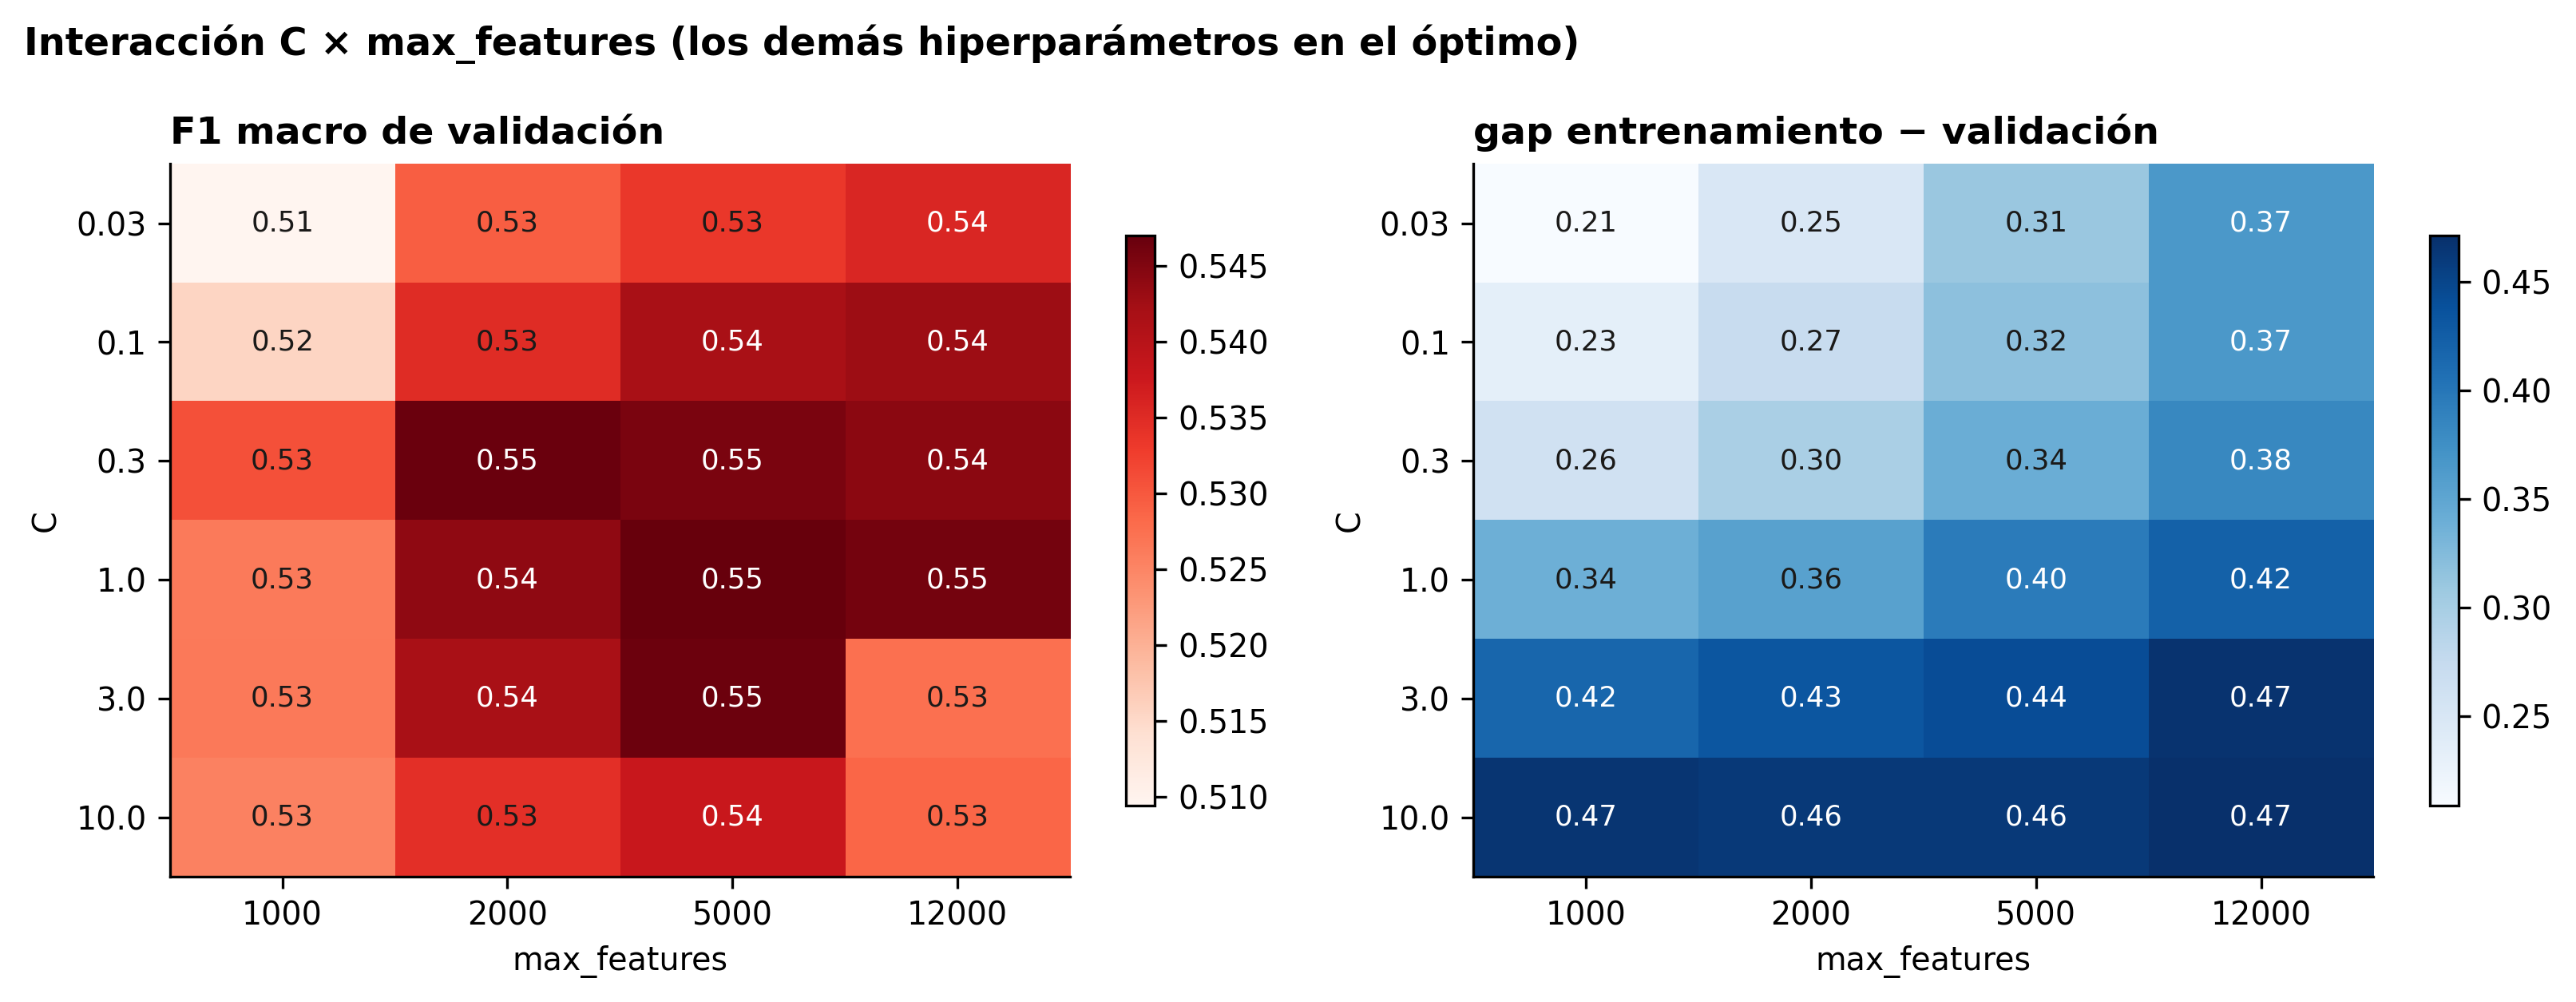

max_features,1000,2000,5000,12000
C,,,,
0.03,0.509,0.529,0.534,0.536
0.10,0.515,0.535,0.542,0.543
0.30,0.531,0.547,0.545,0.544
1.00,0.526,0.544,0.547,0.546
3.00,0.526,0.542,0.547,0.527
10.00,0.526,0.535,0.538,0.529


In [6]:
display(Image(filename=str(FIG / "16_interaccion_C_max_features.png"), width=1000))
display(pd.read_csv(OPT / "interacciones.csv").pivot(index="C", columns="max_features", values="val_f1").round(3))

## 6. Antes y después: cómo se eligió `best_model`

Tres configuraciones evaluadas con la misma validación cruzada:

* **Base** (`C = 1`, 5 000 *features*): la del documento técnico.
* **Óptimo de Optuna**: el ensayo con mayor F1 de validación. Gana décimas, con más sobreajuste.
* **Regla 1-DE** (la adoptada): entre los ensayos cuyo F1 está a menos de una desviación estándar del máximo, el de menor *gap*. Mismo F1 dentro del ruido, 12 pp menos de sobreajuste y menor varianza entre pliegues.

Conclusión honesta del *workshop*: **la optimización no mejora el F1 de validación de forma apreciable** (el error restante es de etiqueta y de tamaño de muestra, como mostró la Semana 3), pero sí permite elegir un modelo igual de bueno y más estable. Esa es la configuración que se guarda como `best_model`.

,configuración,val_f1,val_std,train_f1,gap
0,"Base: C=1, 5 000 feat., 1-2 gramas",0.547,0.020,0.942,0.395
1,"Óptimo Optuna: C=3.041, max_features=8000, ngr...",0.553,0.039,0.994,0.441
2,"Regla 1-DE (menor gap): C=0.156, max_features=...",0.540,0.020,0.813,0.273


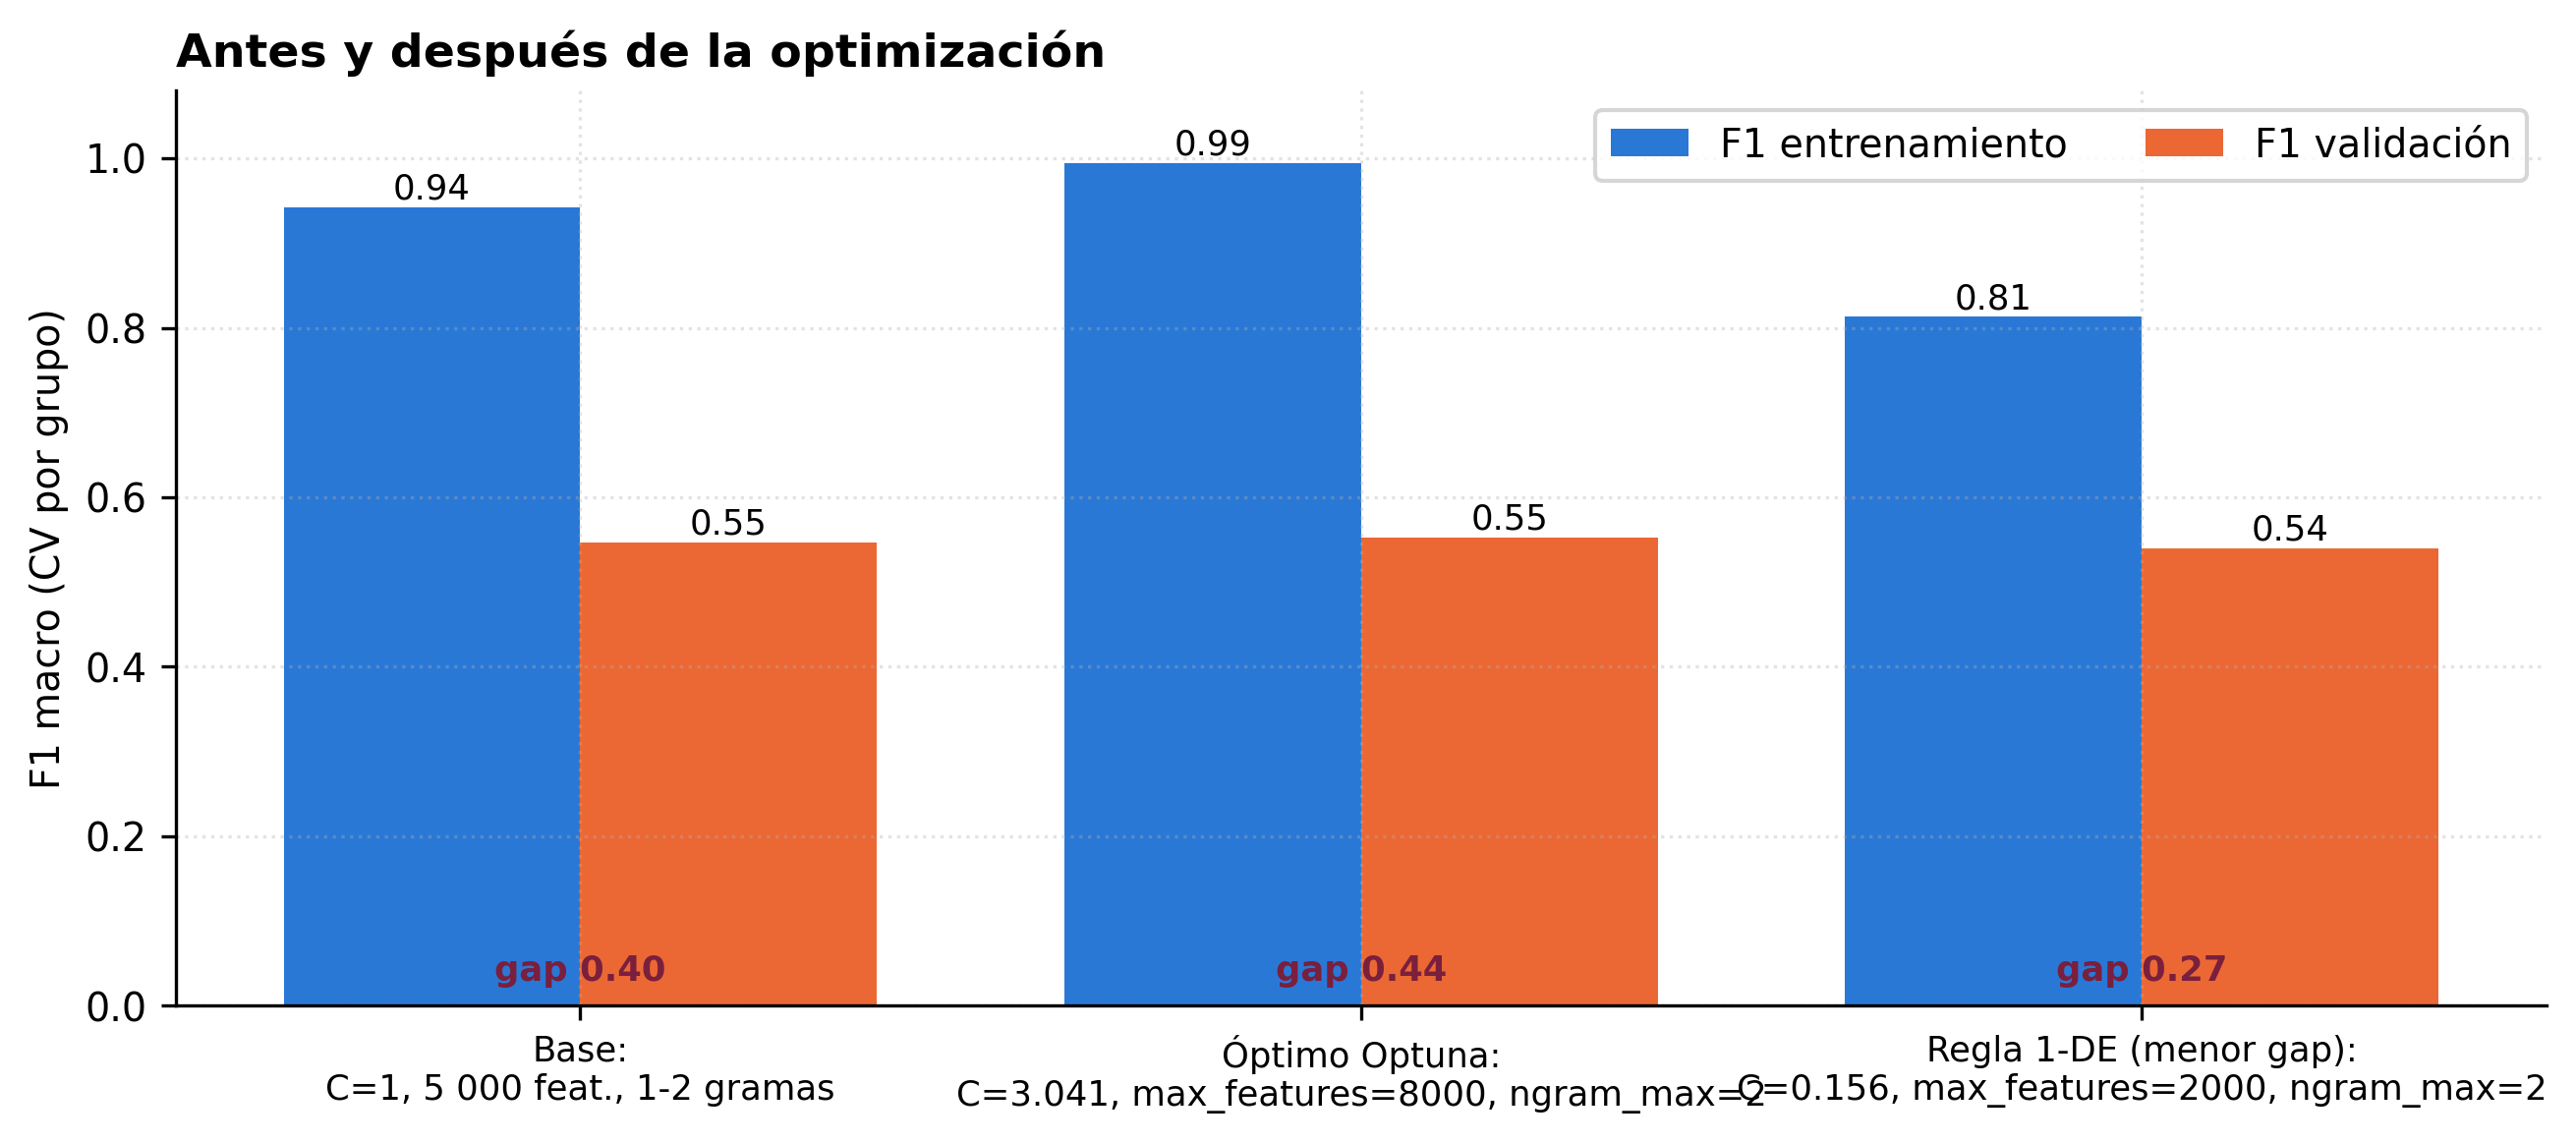

regla 1-DE → {'C': 0.15671405527982937, 'max_features': 2000, 'ngram_max': 2, 'min_df': 1, 'class_weight': 'balanced', 'sublinear_tf': True}


In [7]:
comp = pd.read_csv(OPT / "comparacion_antes_despues.csv"); display(comp.round(3)); display(Image(filename=str(FIG / "17_antes_despues_optimizacion.png"), width=820))
print("regla 1-DE →", resumen["regla_1se"])

## 7. Entrenar y guardar `best_model`

`src/train.py` lee `regla_1se` de `resumen.json`, entrena con todo `train.csv` y guarda `models/best_model.pkl` + metadatos. Es el modelo que sirve la aplicación.

In [8]:
import train as T
from data_processing import load_splits
params, origen = T.best_params(); meta = T.train_and_save("best_model", params, load_splits(cfg)["train"], cfg, origen)
print(json.dumps(meta, ensure_ascii=False, indent=1, default=float))

2026-10-11 04:05:16,140 · INFO · model · modelo guardado en /home/claude/repo_genial/models/best_model.pkl


2026-10-11 04:05:16,142 · INFO · train · best_model: CV val F1 0.540 (gap 0.27) · umbral de confianza 0.29 (tramo automático 15 %, exactitud 0.85) · guardado


{
 "nombre": "best_model",
 "origen_parametros": "results/metrics/optimizacion/resumen.json (regla 1-DE)",
 "n_entrenamiento": 673,
 "cv_por_grupo": {
  "val_f1": 0.5398867950153117,
  "val_std": 0.02031277040846335,
  "train_f1": 0.8128932055797431,
  "gap": 0.2730064105644314
 },
 "f1_entrenamiento": 0.779305545139566,
 "umbral_confianza": 0.29,
 "calibracion_umbral": {
  "criterio": "exactitud del tramo automático ≥ 0.85 con ≥ 10% de normas automáticas (CV por grupo, train)",
  "objetivo_alcanzado": true,
  "umbral": 0.29,
  "fraccion_automatica": 0.150074294205052,
  "exactitud_automatica": 0.8514851485148515,
  "curva": [
   {
    "umbral": 0.2,
    "fraccion_automatica": 1.0,
    "exactitud_automatica": 0.575037147102526
   },
   {
    "umbral": 0.25,
    "fraccion_automatica": 0.5141158989598811,
    "exactitud_automatica": 0.7052023121387283
   },
   {
    "umbral": 0.3,
    "fraccion_automatica": 0.11292719167904904,
    "exactitud_automatica": 0.8552631578947368
   },
   {
  